# Dataset Exploration

The datasets below are used to investigate latent reasoning models.

| Dataset | Purpose |
|---|---|
| **GSM8K** | Grade-school math word problems. Its test set (1,319 problems) is the main evaluation set for every model. |
| **GSM8k-Aug** | GSM8K's training set expanded to $\sim$385k problems. The training data for all models, and the source of the "easy" subset for easy$\rightarrow$hard generalization. |
| **E2H-GSM8K** | The GSM8K test set with a difficulty rating per problem. One way to split test problems into easy and hard. |
| **MATH** | Harder, competition-style math. Used to test in-context learning (ICL) and as out-of-distribution data. |
| **E2H-AMC** | Competition math with human-based difficulty ratings. Out-of-distribution data for the stretch goals. |

Each section covers the dataset's structure, an example, and how its problems are spread across difficulty.

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset

# GSM8K
[openai/gsm8k](https://huggingface.co/datasets/openai/gsm8k)

---

## Summary
Released by OpenAI in 2021: 8.5k grade-school math word problems written by people. Each takes $2\text{-}8$ steps of basic arithmetic.

## Fields
- `question`: the word problem.
- `answer`: the full written solution. Calculations are marked `<<48/2=24>>` and the solution ends with `#### 72`.

## Splits
train 7,473 $\cdot$ test 1,319. There are two configs: `main` and `socratic` (the socratic one adds sub-questions to each solution).

## Source
Cobbe et al. (2021), *Training Verifiers to Solve Math Word Problems*.

## Structure

In [2]:
gsm8k_ds = load_dataset("openai/gsm8k", "main")
print(gsm8k_ds)
print()
gsm8k_train_df = gsm8k_ds["train"].to_pandas()
gsm8k_test_df = gsm8k_ds["test"].to_pandas()
print(f"Train Shape:{gsm8k_train_df.shape}")
print(f"Test Shape:\t{gsm8k_test_df.shape}")

DatasetDict({
    train: Dataset({
        features: ['question', 'answer'],
        num_rows: 7473
    })
    test: Dataset({
        features: ['question', 'answer'],
        num_rows: 1319
    })
})

Train Shape:(7473, 2)
Test Shape:	(1319, 2)


## Example

In [3]:
print(gsm8k_train_df["question"][1])
print()
print(gsm8k_train_df["answer"][1])

Weng earns $12 an hour for babysitting. Yesterday, she just did 50 minutes of babysitting. How much did she earn?

Weng earns 12/60 = $<<12/60=0.2>>0.2 per minute.
Working 50 minutes, she earned 0.2 x 50 = $<<0.2*50=10>>10.
#### 10


## Steps per Problem

In [4]:
gsm8k_train_df["n_steps"] = gsm8k_train_df["answer"].str.count("<<")
gsm8k_test_df["n_steps"]  = gsm8k_test_df["answer"].str.count("<<")

step_dist = pd.DataFrame({
    "train": gsm8k_train_df["n_steps"].value_counts(normalize=True),
    "test":  gsm8k_test_df["n_steps"].value_counts(normalize=True),
}).fillna(0).sort_index()
step_dist.round(3)

,train,test
n_steps,,
0,0.013,0.014
1,0.054,0.049
2,0.291,0.271
3,0.286,0.276
4,0.191,0.220
5,0.105,0.105
6,0.038,0.043
7,0.016,0.016
8,0.005,0.007


In [5]:
pd.DataFrame({
    "train": gsm8k_train_df["n_steps"].describe(),
    "test":  gsm8k_test_df["n_steps"].describe(),
}).round(2)

,train,test
count,7473.00,1319.00
mean,3.17,3.25
std,1.40,1.41
min,0.00,0.00
25%,2.00,2.00
50%,3.00,3.00
75%,4.00,4.00
max,9.00,8.00


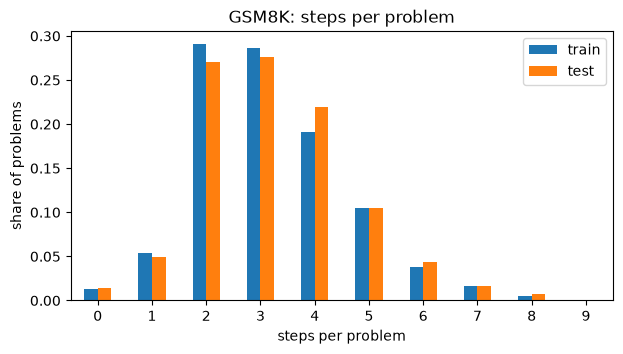

In [6]:
ax = step_dist.plot.bar(rot=0, figsize=(7, 3.5))
ax.set_xlabel("steps per problem")
ax.set_ylabel("share of problems")
ax.set_title("GSM8K: steps per problem")
plt.show()

# GSM8k-Aug
[zen-E/GSM8k-Aug](https://huggingface.co/datasets/zen-E/GSM8k-Aug)

---

## Summary
GSM8K's training set expanded to $\sim$385k problems with synthetic problems generated by GPT-4. The reasoning is reduced to calculations only. COCONUT and CODI both train on it.

## Fields
- `question`: the word problem.
- `cot`: the reasoning steps, calculations only, e.g. `<<600*30/100=180>> <<180+60=240>>`. Each `<<...>>` is one step.
- `answer`: the final answer only, e.g. `360`.

## Splits
train 385,620 and test 1,319 (the test split is the GSM8K test set). COCONUT's copy of this data, from the authors' GitHub, also has a 500-problem validation split.

## Source
Deng et al. (2023), *Implicit Chain of Thought Reasoning via Knowledge Distillation*. This Hugging Face copy is the one CODI uses. A prose-reasoning version is at `zen-E/GSM8k-Aug-NL`.

## Structure

In [7]:
aug_ds = load_dataset("zen-E/GSM8k-Aug")
print(aug_ds)
print()
aug_train_df = aug_ds["train"].to_pandas()
aug_test_df  = aug_ds["test"].to_pandas()
print(f"Train Shape:{aug_train_df.shape}")
print(f"Test Shape:\t{aug_test_df.shape}")

DatasetDict({
    train: Dataset({
        features: ['question', 'cot', 'answer'],
        num_rows: 385620
    })
    test: Dataset({
        features: ['question', 'cot', 'answer'],
        num_rows: 1319
    })
})

Train Shape:(385620, 3)
Test Shape:	(1319, 3)


## Example

In [8]:
print(aug_train_df["question"][1])
print()
print(aug_train_df["cot"][1])
print()
print(aug_train_df["answer"][1])

Rebecca sets aside 20% of her weekly salary to savings. If she manages to save $150 during a week, how much does she earn?

<<150/0.2=750>>

750


## Steps per Problem

In [9]:
aug_train_df["n_steps"] = aug_train_df["cot"].str.count("<<")
aug_test_df["n_steps"]  = aug_test_df["cot"].str.count("<<")

step_dist = pd.DataFrame({
    "GSM8K train": gsm8k_train_df["n_steps"].value_counts(normalize=True),
    "Aug train":   aug_train_df["n_steps"].value_counts(normalize=True),
    "Aug test":    aug_test_df["n_steps"].value_counts(normalize=True),
}).fillna(0).sort_index()
step_dist.round(3)

,GSM8K train,Aug train,Aug test
n_steps,,,
0,0.013,0.000,0.014
1,0.054,0.163,0.049
2,0.291,0.372,0.271
3,0.286,0.270,0.276
4,0.191,0.125,0.220
5,0.105,0.046,0.105
6,0.038,0.015,0.043
7,0.016,0.006,0.016
8,0.005,0.001,0.007


In [10]:
pd.DataFrame({
    "train": aug_train_df["n_steps"].describe(),
    "test":  aug_test_df["n_steps"].describe(),
}).round(2)

,train,test
count,385620.00,1319.00
mean,2.60,3.25
std,1.21,1.41
min,0.00,0.00
25%,2.00,2.00
50%,2.00,3.00
75%,3.00,4.00
max,13.00,8.00


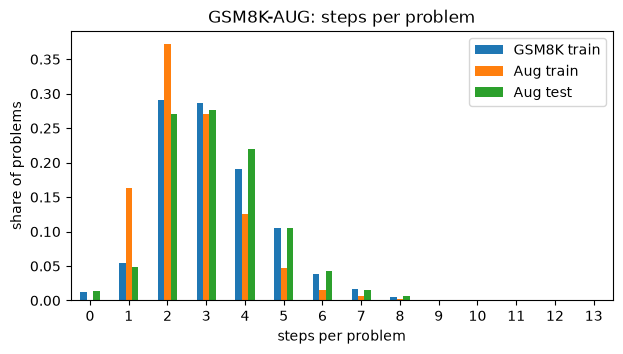

In [11]:
ax = step_dist.plot.bar(rot=0, figsize=(7, 3.5))
ax.set_xlabel("steps per problem")
ax.set_ylabel("share of problems")
ax.set_title("GSM8K-AUG: steps per problem")
plt.show()

# E2H-GSM8K
[furonghuang-lab/Easy2Hard-Bench](https://huggingface.co/datasets/furonghuang-lab/Easy2Hard-Bench) (config `E2H-GSM8K`)

---

## Summary
The 1,319 GSM8K test problems, each with a difficulty rating. The rating was estimated with Item Response Theory from which LLMs on the Open LLM Leaderboard solved the problem.

## Fields
- `question`, `answer`: same as GSM8K.
- `rating`: difficulty, 0 (easy) to 1 (hard).
- `rating_quantile`, `rating_std`: the rating's percentile and its uncertainty.
- `model_avg_acc`: the share of the selected LLMs that answered the problem correctly.

## Splits
eval 1,319 (no training split).

## Source
Ding et al. (2024), *Easy2Hard-Bench: Standardized Difficulty Labels for Profiling LLM Performance and Generalization*.

## Structure

In [12]:
e2h_gsm8k_ds = load_dataset("furonghuang-lab/Easy2Hard-Bench", "E2H-GSM8K")
print(e2h_gsm8k_ds)
print()
e2h_gsm8k_df = e2h_gsm8k_ds["eval"].to_pandas()
print(f"Eval Shape:{e2h_gsm8k_df.shape}")
print(f"Same questions as GSM8K test: {set(e2h_gsm8k_df['question']) == set(gsm8k_test_df['question'])}")

DatasetDict({
    eval: Dataset({
        features: ['rating', 'rating_std', 'rating_quantile', 'question', 'answer', 'model_avg_acc', 'unnorm_rating', 'unnorm_rating_std'],
        num_rows: 1319
    })
})

Eval Shape:(1319, 8)
Same questions as GSM8K test: True


## Example

In [13]:
print(e2h_gsm8k_df["question"][1])
print()
print(e2h_gsm8k_df["answer"][1])
print()
print(f"Rating: {e2h_gsm8k_df['rating'][1]:.3f}")
print(f"Model avg acc: {e2h_gsm8k_df['model_avg_acc'][1]:.3f}")

100 people apply for a job at Google. Of the people that apply, only 30% receive interviews. Of those who receive interviews, 20% receive a job offer. Of those who receive a job offer, a third of the people accept the position. How many people accept the position?

The number of people that receive interviews is 100 * 0.30 = <<100*0.30=30>>30 people
The number of people that receive a job offer is 30 * 0.20 = <<30*0.20=6>>6 people
The number of people that accept the position is 6 / 3 = <<6/3=2>>2 people
#### 2

Rating: 0.132
Model avg acc: 0.108


## Difficulty Rating

In [14]:
e2h_gsm8k_df["rating"].describe().round(3)

count    1319.000
mean        0.454
std         0.220
min         0.000
25%         0.271
50%         0.438
75%         0.625
max         1.000
Name: rating, dtype: float64

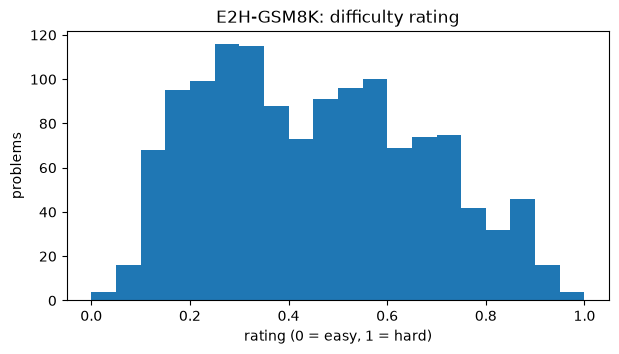

In [15]:
ax = e2h_gsm8k_df["rating"].plot.hist(bins=20, figsize=(7, 3.5))
ax.set_xlabel("rating (0 = easy, 1 = hard)")
ax.set_ylabel("problems")
ax.set_title("E2H-GSM8K: difficulty rating")
plt.show()

## Rating vs. Steps per Problem

In [16]:
e2h_gsm8k_df["n_steps"] = e2h_gsm8k_df["answer"].str.count("<<")

e2h_gsm8k_df.groupby("n_steps")["rating"].agg(["count", "mean"]).round(3)

,count,mean
n_steps,,
0,18,0.547
1,65,0.464
2,357,0.375
3,364,0.426
4,290,0.493
5,138,0.536
6,57,0.602
7,21,0.622
8,9,0.620


# MATH
[EleutherAI/hendrycks_math](https://huggingface.co/datasets/EleutherAI/hendrycks_math)

---

## Summary
12.5k competition math problems (AMC, AIME, etc.) across 7 subjects, each rated by difficulty from Level 1 to Level 5. Written in LaTeX.

## Fields
- `problem`: the problem statement. Some include figures written as `[asy]` drawing code.
- `level`: `Level 1` to `Level 5`.
- `type`: the subject.
- `solution`: the full written solution, with the final answer in `\boxed{...}`.

## Splits
train 7,500 $\cdot$ test 5,000, with one config per subject: algebra, counting_and_probability, geometry, intermediate_algebra, number_theory, prealgebra, precalculus.

## Source
Hendrycks et al. (2021), *Measuring Mathematical Problem Solving With the MATH Dataset*. This is EleutherAI's mirror of the original.

## Structure

In [17]:
math_subjects = ["algebra", "counting_and_probability", "geometry", "intermediate_algebra",
                 "number_theory", "prealgebra", "precalculus"]

math_ds = {subject: load_dataset("EleutherAI/hendrycks_math", subject) for subject in math_subjects}
print(math_ds["algebra"])
print()
math_train_df = pd.concat([ds["train"].to_pandas() for ds in math_ds.values()], ignore_index=True)
math_test_df  = pd.concat([ds["test"].to_pandas() for ds in math_ds.values()], ignore_index=True)
print(f"Train Shape:{math_train_df.shape}")
print(f"Test Shape:\t{math_test_df.shape}")

DatasetDict({
    train: Dataset({
        features: ['problem', 'level', 'type', 'solution'],
        num_rows: 1744
    })
    test: Dataset({
        features: ['problem', 'level', 'type', 'solution'],
        num_rows: 1187
    })
})

Train Shape:(7500, 4)
Test Shape:	(5000, 4)


## Example

In [18]:
print(f"{math_train_df['type'][1]}, {math_train_df['level'][1]}")
print()
print(math_train_df["problem"][1])
print()
print(math_train_df["solution"][1])

Algebra, Level 5

A rectangular band formation is a formation with $m$ band members in each of $r$ rows, where $m$ and $r$ are integers. A particular band has less than 100 band members. The director arranges them in a rectangular formation and finds that he has two members left over. If he increases the number of members in each row by 1 and reduces the number of rows by 2, there are exactly enough places in the new formation for each band member. What is the largest number of members the band could have?

Let $x$ be the number of band members in each row for the original formation, when two are left over.  Then we can write two equations from the given information: $$rx+2=m$$ $$(r-2)(x+1)=m$$ Setting these equal, we find: $$rx+2=(r-2)(x+1)=rx-2x+r-2$$ $$2=-2x+r-2$$ $$4=r-2x$$ We know that the band has less than 100 members.  Based on the first equation, we must have $rx$ less than 98.  We can guess and check some values of $r$ and $x$ in the last equation.  If $r=18$, then $x=7$, and

## Problems per Level

In [19]:
level_dist = pd.DataFrame({
    "train": math_train_df["level"].value_counts(normalize=True),
    "test":  math_test_df["level"].value_counts(normalize=True),
}).fillna(0).sort_index()
level_dist.round(3)

,train,test
level,,
Level 1,0.075,0.087
Level 2,0.180,0.179
Level 3,0.212,0.226
Level 4,0.225,0.243
Level 5,0.307,0.265
Level ?,0.000,0.000


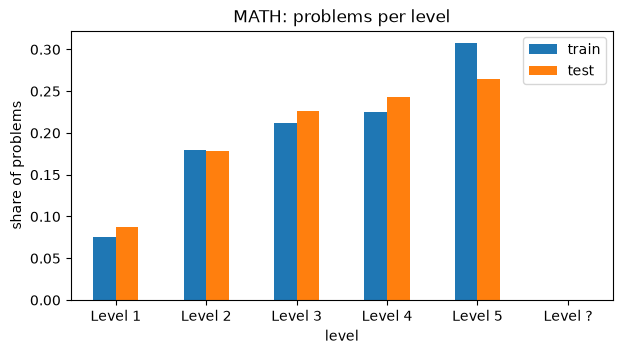

In [20]:
ax = level_dist.plot.bar(rot=0, figsize=(7, 3.5))
ax.set_xlabel("level")
ax.set_ylabel("share of problems")
ax.set_title("MATH: problems per level")
plt.show()

## Test Problems per Subject and Level

In [21]:
pd.crosstab(math_test_df["type"], math_test_df["level"], margins=True, margins_name="Total")

level,Level 1,Level 2,Level 3,Level 4,Level 5,Total
type,,,,,,
Algebra,135,201,261,283,307,1187
Counting & Probability,39,101,100,111,123,474
Geometry,38,82,102,125,132,479
Intermediate Algebra,52,128,195,248,280,903
Number Theory,30,92,122,142,154,540
Prealgebra,86,177,224,191,193,871
Precalculus,57,113,127,114,135,546
Total,437,894,1131,1214,1324,5000


# E2H-AMC
[furonghuang-lab/Easy2Hard-Bench](https://huggingface.co/datasets/furonghuang-lab/Easy2Hard-Bench)

---

## Summary
Competition math problems from AMC 8/10/12, AIME and HMMT, each with a difficulty rating. Unlike E2H-GSM8K, the rating comes from how human contestants performed.

## Fields
- `problem`, `answer`, `solution`: the problem, its final answer, and a written solution.
- `contest`, `year`: where the problem came from.
- `rating`: difficulty, 0 (easy) to 1 (hard).
- `rating_quantile`, `rating_std`: the rating's percentile and its uncertainty.

## Splits
train 1,000 $\cdot$ eval 2,975 (eval contains 1,466 AMC, 216 AIME and 1,293 HMMT problems).

## Source
Ding et al. (2024), *Easy2Hard-Bench: Standardized Difficulty Labels for Profiling LLM Performance and Generalization*.

## Structure

In [22]:
e2h_amc_ds = load_dataset("furonghuang-lab/Easy2Hard-Bench", "E2H-AMC")
print(e2h_amc_ds)
print()
e2h_amc_train_df = e2h_amc_ds["train"].to_pandas()
e2h_amc_eval_df  = e2h_amc_ds["eval"].to_pandas()
print(f"Train Shape:{e2h_amc_train_df.shape}")
print(f"Eval Shape:\t{e2h_amc_eval_df.shape}")

DatasetDict({
    train: Dataset({
        features: ['contest', 'rating', 'rating_std', 'rating_quantile', 'tag', 'subtest', 'year', 'month', 'index', 'problem', 'answer', 'solution', 'rating_tag', 'test_tag', 'item_difficulty', 'unnorm_rating', 'unnorm_rating_std', 'unnorm_rating_lower', 'unnorm_rating_upper', 'ever_exist'],
        num_rows: 1000
    })
    eval: Dataset({
        features: ['contest', 'rating', 'rating_std', 'rating_quantile', 'tag', 'subtest', 'year', 'month', 'index', 'problem', 'answer', 'solution', 'rating_tag', 'test_tag', 'item_difficulty', 'unnorm_rating', 'unnorm_rating_std', 'unnorm_rating_lower', 'unnorm_rating_upper', 'ever_exist'],
        num_rows: 2975
    })
})

Train Shape:(1000, 20)
Eval Shape:	(2975, 20)


## Example

In [23]:
print(f"{e2h_amc_eval_df['contest'][1]} {e2h_amc_eval_df['year'][1]}, rating {e2h_amc_eval_df['rating'][1]:.3f}")
print()
print(e2h_amc_eval_df["problem"][1])
print()
print(f"Answer: {e2h_amc_eval_df['answer'][1]}")

HMMT 2021, rating 0.490

Let $n$ be the answer to this problem. The polynomial $x^{n}+a x^{2}+b x+c$ has real coefficients and exactly $k$ real roots. Find the sum of the possible values of $k$.

Answer: 10


## Difficulty Rating

In [24]:
pd.DataFrame({
    "train": e2h_amc_train_df["rating"].describe(),
    "eval":  e2h_amc_eval_df["rating"].describe(),
}).round(3)

,train,eval
count,1000.000,2975.000
mean,0.441,0.436
std,0.244,0.245
min,0.004,0.000
25%,0.242,0.239
50%,0.410,0.392
75%,0.645,0.661
max,0.945,1.000


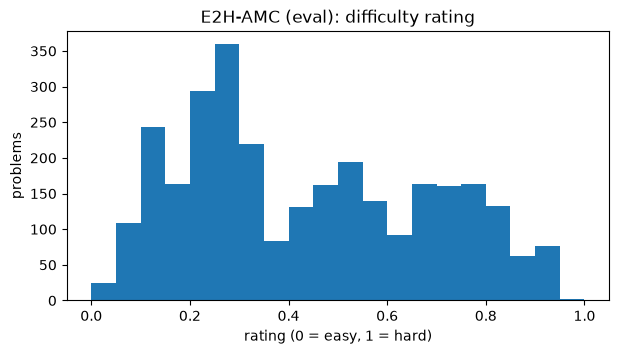

In [25]:
ax = e2h_amc_eval_df["rating"].plot.hist(bins=20, figsize=(7, 3.5))
ax.set_xlabel("rating (0 = easy, 1 = hard)")
ax.set_ylabel("problems")
ax.set_title("E2H-AMC (eval): difficulty rating")
plt.show()

## Difficulty by Contest (eval)

In [26]:
e2h_amc_eval_df.groupby("contest")["rating"].agg(["count", "mean"]).round(3)

,count,mean
contest,,
AIME,216,0.572
AMC,1466,0.221
HMMT,1293,0.657
